### Task 1
For the statement 1 of task 1, we are going to implement the gradient descent method with backtracking from the Practical 2, where we defined it previously. Observe that we modify the parameters of the functions $f$ and $df$, so they have into account the set of sample points. Also, we added the condition of alpha>1e-12 because elsewise the alpha approximates to practically 0, and the inner loop never stops, because there is very little variation in the actual point and the next point (numerically). Also, we add that if alpha is less or equal than 1e-12, then the algorithm stops. 

We also set a maximum of 10000 iterations to avoid an unlimited loop. If this limit is reached, the function prints a message; the returned point must not automatically be considered converged.


In [1]:

def gradient_descent_backtrack(f, df, starting_point, points, max_iter=10000):
    
    (x_1, x_2) = starting_point
    traj_points = [(x_1, x_2)]
    for _ in range(max_iter):
        gradient = df(points, x_1, x_2)
        if np.linalg.norm(gradient) < 1e-5: # we arbitrarily choose this as tolerance.
            break

        alpha=1
        while alpha>1e-12 and f(points, x_1, x_2) <= f(points, x_1 - alpha*gradient[0], x_2 - alpha*gradient[1]):
            alpha = alpha/2
        if alpha <= 1e-12:
            break
        x_1 -= alpha*gradient[0]
        x_2 -= alpha*gradient[1]
        traj_points.append((x_1, x_2))

    else:
        print("Maximum iterations reached; check convergence.")

    return traj_points

        

In [2]:
import math
import numpy as np

np.random.seed(42) # Reproduce the same samples when running all cells.

m = [0.,0.]
angle = 45*math.pi/180
rot = np.array([[math.cos(angle),-math.sin(angle)], [math.sin(angle),
math.cos(angle)]])
lamb = np.array([[100,0],[0,1]])
s = np.matmul(rot, np.matmul(lamb, rot.transpose()))
points = np.random.multivariate_normal(m,s,100)


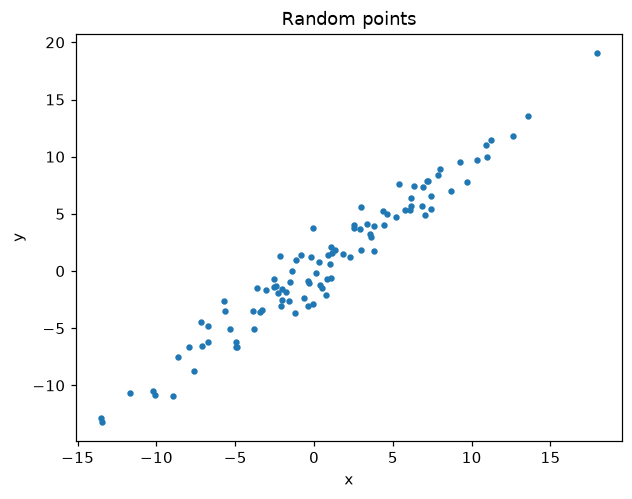

In [3]:
import matplotlib.pyplot as plt

plt.scatter(points[:, 0], points[:, 1], s=10)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Random points")
plt.show()

To approach the problem, we first define the function and it's derivative. 

In [4]:
def Q(points, w_0, w_1):
    suma = w_0*points[:, 0] + w_1 - points[:, 1]
    return (1/2)*np.sum(suma**2)

def dQ(points, w_0, w_1):
    comsum = (w_0*points[:,0] + w_1 - points[:,1])
    dw0 = np.sum(comsum*points[:,0])
    dw1 = np.sum(comsum)
    return np.array([dw0, dw1])


Now, having defined the definition of functions, we intend to find the minimum values of $(w_0, w_1)$ using `gradient_descent_backtrack`:

In [5]:
path = gradient_descent_backtrack(Q, dQ, (1,2), points)


Now, having found the values of $(w_0, w_1)$ that minimise the least squares error function, we can draw a plot of how "good" does the line with these values fit the points:

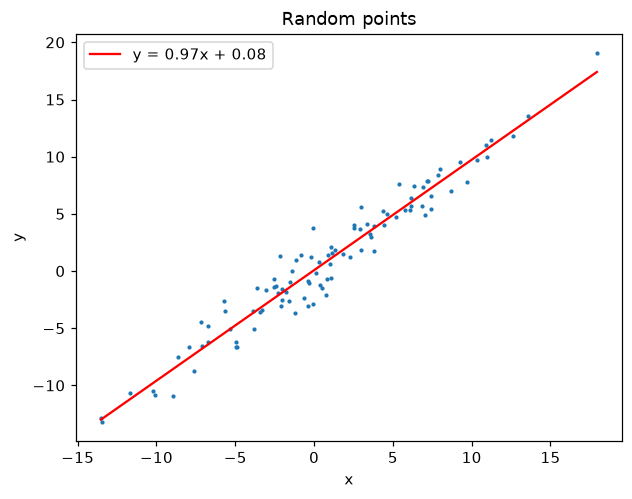

In [6]:
plt.scatter(points[:, 0], points[:, 1], s=3)
x_line = np.array([points[:, 0].min(), points[:, 0].max()])
plt.plot(x_line, path[-1][0]*x_line + path[-1][1], color="red", label=f"y = {path[-1][0]:.2f}x + {path[-1][1]:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Random points")

So we observe that with the parameters extracted using gradient descent, the line fits very well to the sample points. In reality, what it does is minimises the average distance from the real sample point $y$, to what we reach with the linear regression, say $\hat{y}$. 

For statement 2, let's edit the code of sample points so there is an outlier, and see how the line with new parameters $(\tilde{w_0}, \tilde{w_1})$ behave. 

In [7]:
m = [0.,0.]
angle = 45*math.pi/180
rot = np.array([[math.cos(angle),-math.sin(angle)], [math.sin(angle),
math.cos(angle)]])
lamb = np.array([[100,0],[0,1]])
s = np.matmul(rot, np.matmul(lamb, rot.transpose()))
points_outl1 = np.random.multivariate_normal(m,s,100)
points_outl1[1] = [-40, 20]

In [8]:
path_ = gradient_descent_backtrack(Q, dQ, (1,2), points_outl1)


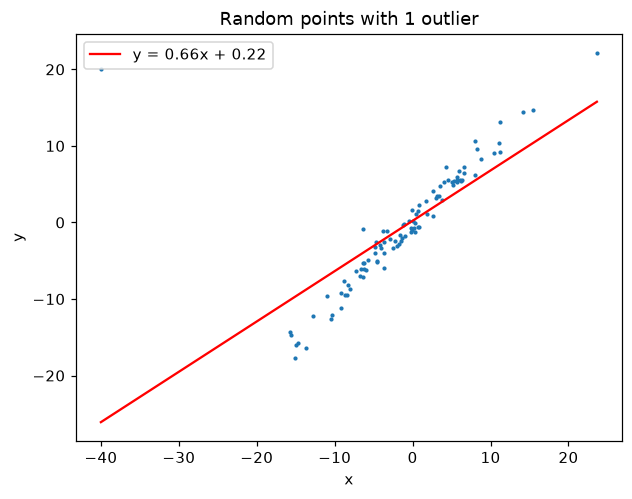

In [9]:
plt.scatter(points_outl1[:, 0], points_outl1[:, 1], s=3)
x_line_ = np.array([points_outl1[:, 0].min(), points_outl1[:, 0].max()])
plt.plot(x_line_, path_[-1][0]*x_line_ + path_[-1][1], color="red", label=f"y = {path_[-1][0]:.2f}x + {path_[-1][1]:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Random points with 1 outlier")


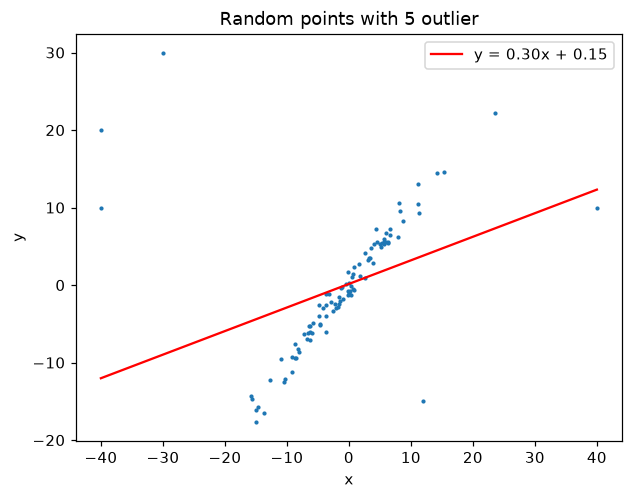

In [10]:
points_outl1[2] = [40, 10]
points_outl1[3] = [12, -15]
points_outl1[4] = [-30, 30]
points_outl1[5] = [-40, 10]
path_ = gradient_descent_backtrack(Q, dQ, (1,2), points_outl1)
plt.scatter(points_outl1[:, 0], points_outl1[:, 1], s=3)
x_line_ = np.array([points_outl1[:, 0].min(), points_outl1[:, 0].max()])
plt.plot(x_line_, path_[-1][0]*x_line_ + path_[-1][1], color="red", label=f"y = {path_[-1][0]:.2f}x + {path_[-1][1]:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Random points with 5 outlier")
plt.show()

We can observe that due to the outlier points $X = [-40, 20]$, values of parameters $(w_0, w_1)$ are changed because the function also had to minimize the value of $(\hat{x}, \hat{y})$ relative to $X$. 

### Task 2

First of all, we define the robust error functions defined in the practical: 
$$\rho_{1}(u) = \frac{1}{2}u^2,$$
$$\rho_{2}(u) = \frac{c^2}{2}\log\left[1+\left(\frac{u}{c}\right)^2\right], \quad c \in \mathbb{R}$$


In [11]:
def ro_1(u):
    return (u**2)/2

def ro_2(c, u):
    frac = (c**2)/2
    interior_log = 1 + (u/c)**2
    log = np.log(interior_log)
    return frac*log

def sum_ro_2(points, w_0, w_1, c):
    u = w_0*points[:,0] + w_1 - points[:,1]
    return np.sum(ro_2(c, u))

Statement 1

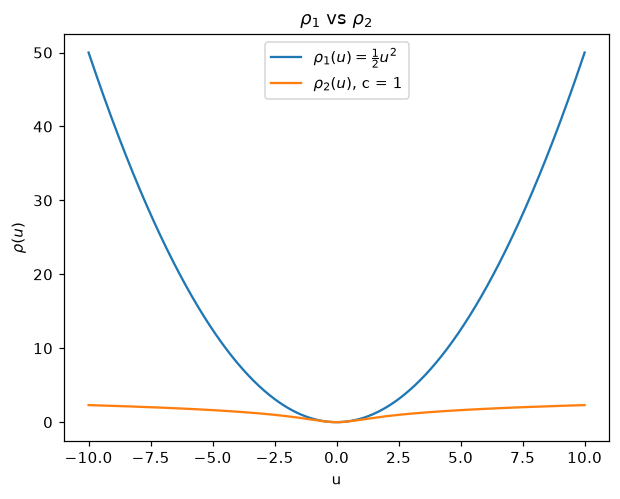

In [12]:
x = np.linspace(-10, 10, 1000)
y = (x**2)/2
c = 1
plt.plot(x, y, label=r"$\rho_{1}(u) = \frac{1}{2}u^2$")
plt.plot(x, ro_2(c, x), label=rf"$\rho_{{2}}(u)$, c = {c}")
plt.xlabel("u")
plt.ylabel(r"$\rho(u)$")
plt.legend()
plt.title(r"$\rho_{1}$ vs $\rho_{2}$")
plt.show()


Statement 2

In [13]:
def dro_2(points, w_0, w_1, c):
    num = w_0*points[:,0] + w_1 - points[:,1]
    den = c**2 + num**2

    ratio = (c**2)*num/den

    dw0 = np.sum(ratio*points[:,0])
    dw1 = np.sum(ratio)
    return np.array([dw0, dw1])



We intend to find the minimum values of $(w_0, w_1)$ using `gradient_descent_backtrack`:

In [14]:
path = gradient_descent_backtrack(
    lambda points, w_0, w_1: sum_ro_2(points, w_0, w_1, c=1),
    lambda points, w_0, w_1: dro_2(points, w_0, w_1, c=1),
    (1., 2.),
    points
)


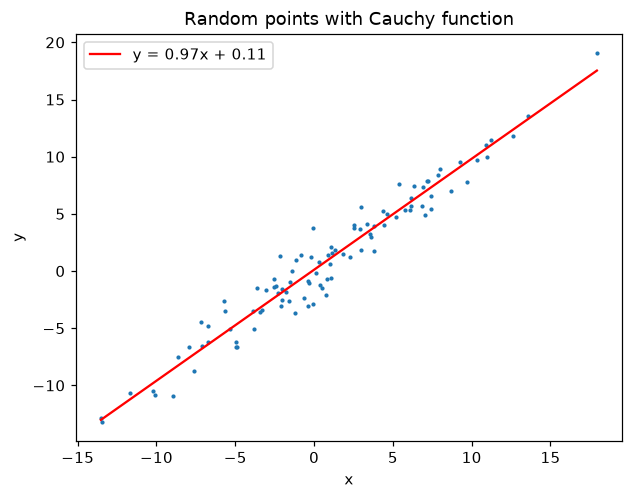

In [15]:
plt.scatter(points[:, 0], points[:, 1], s=3)
x_line = np.array([points[:, 0].min(), points[:, 0].max()])
plt.plot(x_line, path[-1][0]*x_line + path[-1][1], color="red", label=f"y = {path[-1][0]:.2f}x + {path[-1][1]:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Random points with Cauchy function")
plt.show()


Statement 3. Compare

Statement 4.

In [16]:
path_ = gradient_descent_backtrack(
    lambda points_outl1, w_0, w_1: sum_ro_2(points_outl1, w_0, w_1, c=1),
    lambda points_outl1, w_0, w_1: dro_2(points_outl1, w_0, w_1, c=1),
    (1., 2.),
    points_outl1
)


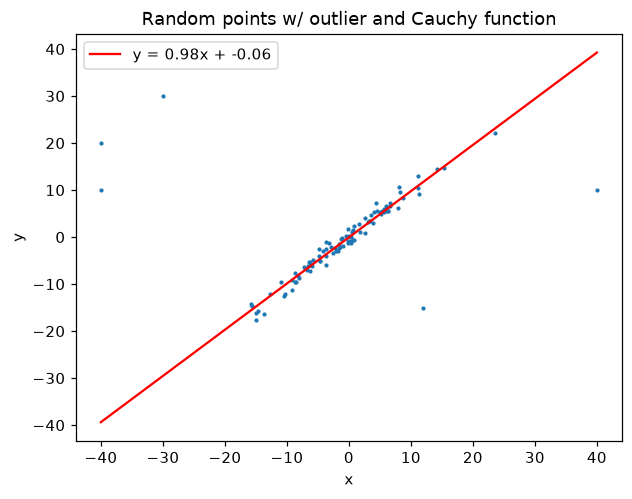

In [17]:
plt.scatter(points_outl1[:, 0], points_outl1[:, 1], s=3)
x_line_ = np.array([points_outl1[:, 0].min(), points_outl1[:, 0].max()])
plt.plot(x_line_, path_[-1][0]*x_line_ + path_[-1][1], color="red", label=f"y = {path_[-1][0]:.2f}x + {path_[-1][1]:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("Random points w/ outlier and Cauchy function")
plt.show()


Statement 5. 

Maximum iterations reached; check convergence.


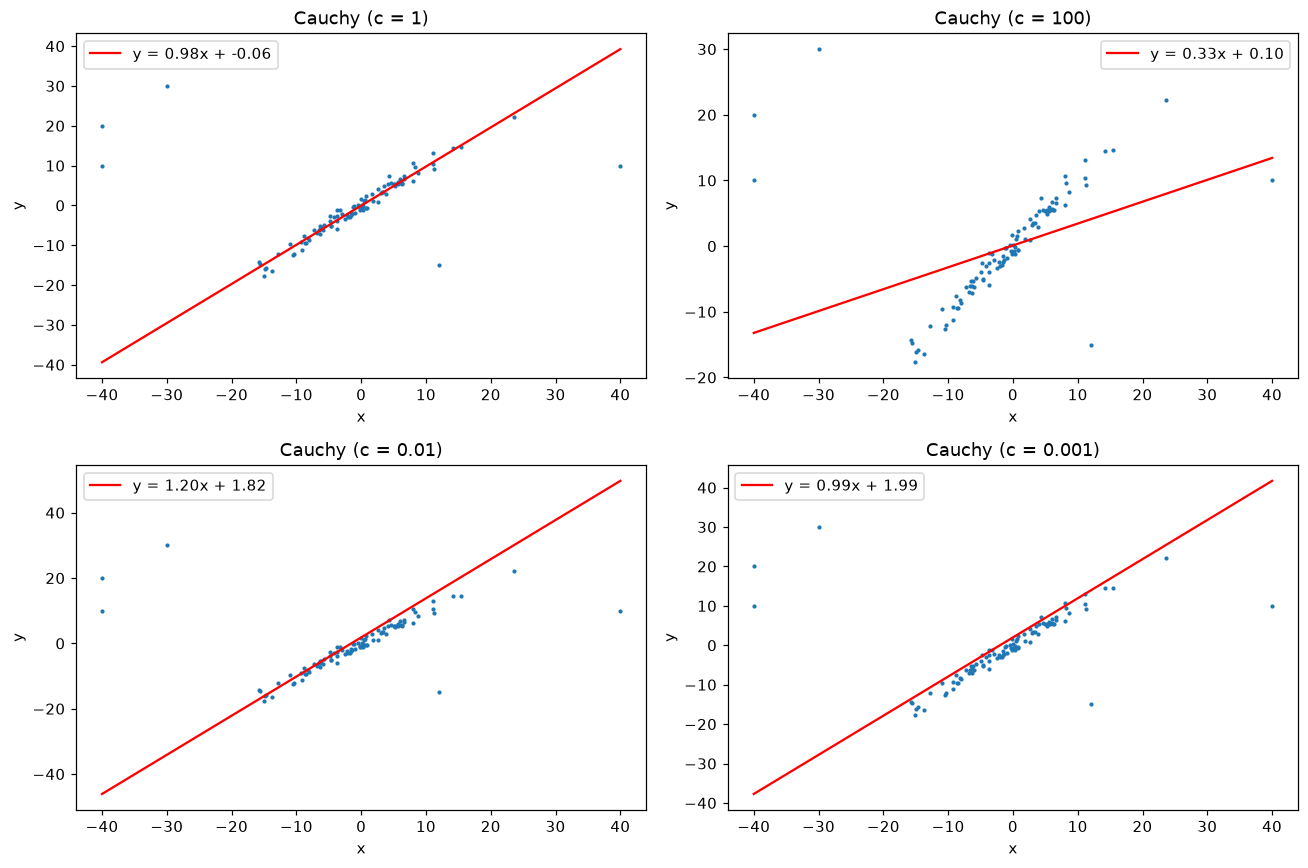

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
c_values = [1, 100, 1/100, 1/1000]
x_line = np.array([points_outl1[:, 0].min(), points_outl1[:, 0].max()])

weights = {}
for i in range(4):
    c = c_values[i]
    ax = axes.flat[i]

    path = gradient_descent_backtrack(
        lambda points, w0, w1: sum_ro_2(points, w0, w1, c=c),
        lambda points, w0, w1: dro_2(points, w0, w1, c=c),
        (1., 2.),
        points_outl1
    )

    w0, w1 = path[-1]
    weights[c] = (w0, w1)

    ax.scatter(points_outl1[:, 0], points_outl1[:, 1], s=3)
    ax.plot(x_line, w0*x_line + w1, color="red",
            label=f"y = {w0:.2f}x + {w1:.2f}")
    ax.set(xlabel="x", ylabel="y", title=f"Cauchy (c = {c})")
    ax.legend()

plt.tight_layout()
plt.show()

Now, let's plot the histogram of the error function $|u|$:

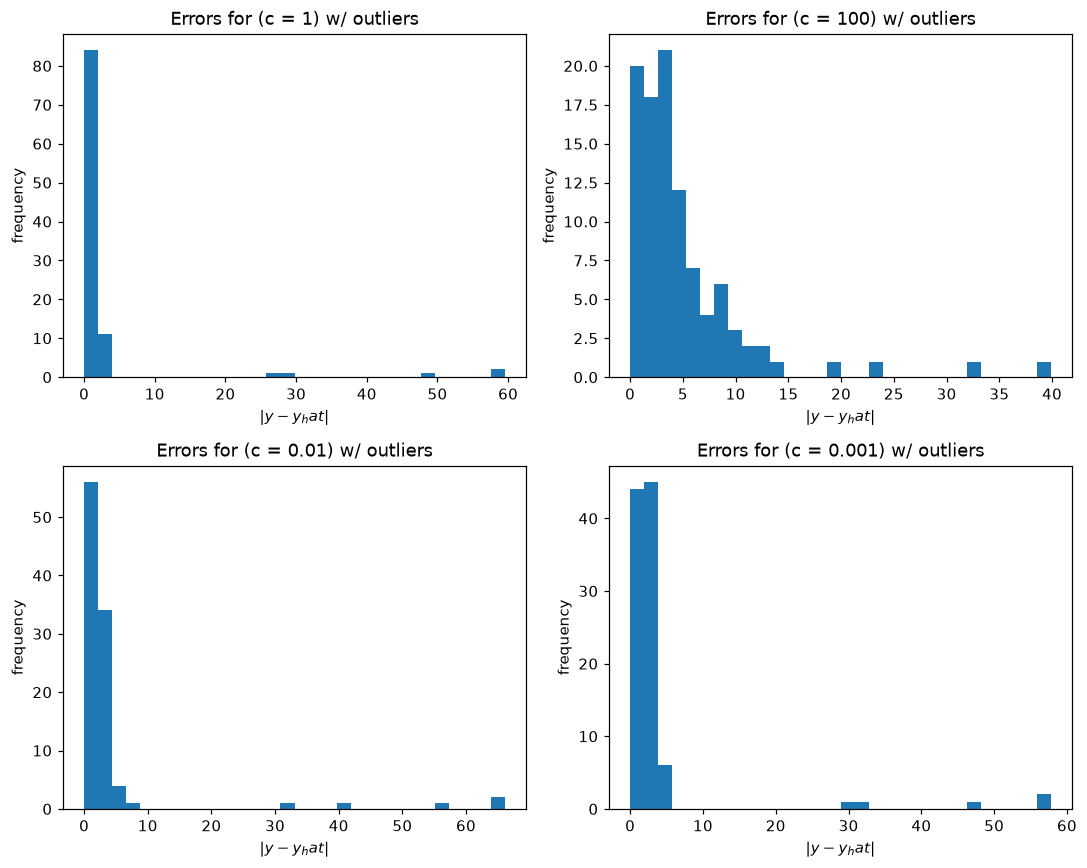

In [19]:
fig, axes = plt.subplots(2,2, figsize=(10,8))

for i in range(4):
    c = c_values[i]
    ax = axes.flat[i]
    w0, w1 = weights[c]
    y_hat = w0 * points_outl1[:,0] + w1
    error = np.abs(points_outl1[:,1] - y_hat)
    ax.hist(error, bins = 30)
    ax.set(xlabel="$|y - y_hat|$", ylabel="frequency", title=f"Errors for (c = {c}) w/ outliers")

plt.tight_layout()
plt.show()


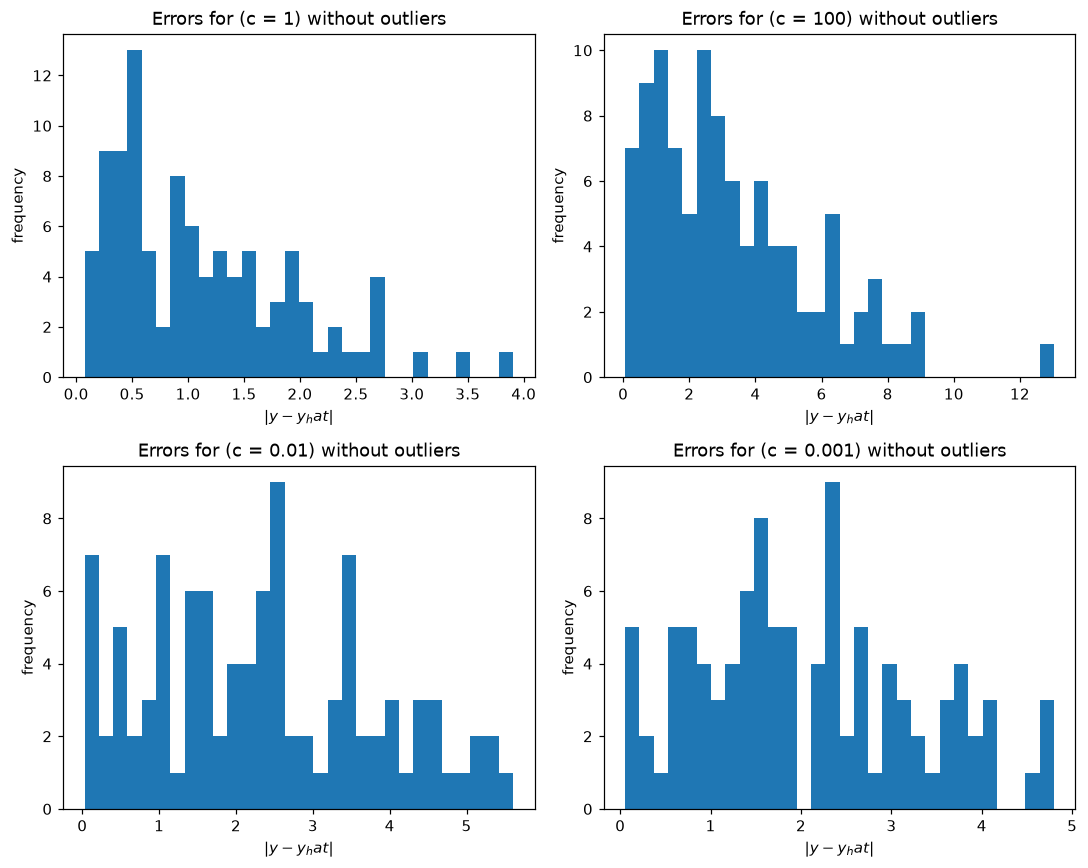

In [20]:
fig, axes = plt.subplots(2,2, figsize=(10,8))

for i in range(4):
    c = c_values[i]
    ax = axes.flat[i]
    w0, w1 = weights[c]
    y_hat = w0 * points[:,0] + w1
    error = np.abs(points[:,1] - y_hat)
    ax.hist(error, bins = 30)
    ax.set(xlabel="$|y - y_hat|$", ylabel="frequency", title=f"Errors for (c = {c}) without outliers")

plt.tight_layout()
plt.show()


Consider performing zoom of the cauchy function

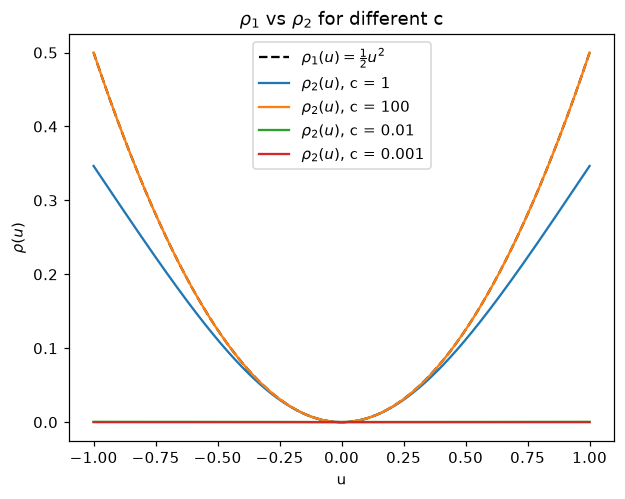

In [21]:
x = np.linspace(1, -1, 1000)

plt.plot(x, (x**2)/2, "k--", label=r"$\rho_{1}(u) = \frac{1}{2}u^2$")
for c in c_values:
    plt.plot(x, ro_2(c, x), label=rf"$\rho_{{2}}(u)$, c = {c}")

plt.xlabel("u")
plt.ylabel(r"$\rho(u)$")
plt.legend()
plt.title(r"$\rho_{1}$ vs $\rho_{2}$ for different c")
plt.show()


Statement 6.

Now, we are going to gradually add more random points to see how the Cauchy function behaves when the number of outliers increases. We use $c=1$ and $c=1/100$, as proposed in the practical.

We generate the random points once, uniformly in $[-50,50]\times[-50,50]$. We always add the first $n$ of these points to the same original dataset, so each experiment contains the points added in the previous experiment. Some random points may fall near the original line; therefore, they are potential outliers, not necessarily all large-residual observations.


In [22]:
rng = np.random.default_rng(42)
outliers = rng.uniform(-50, 50, size=(3000, 2))
n_outliers_values = [0, 10, 100, 500, 1000, 3000]
c_values_6 = [1, 1/100]

datasets_6 = {}
for n in n_outliers_values:
    datasets_6[n] = np.vstack([points, outliers[:n]])


For each value of $c$, we draw the fitted line for the different numbers of added points. As before, we use `gradient_descent_backtrack`, `sum_ro_2` and `dro_2`.

We divide both the function and its gradient by $Nc^2$, where $N$ is the total number of points. This positive scaling does not change the minimisers. It removes the small $c^2$ factor from the gradient and keeps the scale comparable when the number of points changes, so the stopping tolerance is more meaningful.

We try starting at $(1,2)$ and $(0,0)$ and keep the fit with the smallest Cauchy error. This helps reduce the effect of the initial point, but does not guarantee the global minimum because the Cauchy objective is not convex. The gradient descent also has a maximum number of iterations; we check its final gradient in the printed results.


c=1, added=0: w0=0.971, w1=0.115, RMSE=1.391, gradient norm=8.91e-06
c=1, added=10: w0=0.972, w1=0.122, RMSE=1.392, gradient norm=9.86e-06
c=1, added=100: w0=0.921, w1=0.155, RMSE=1.417, gradient norm=9.19e-06
c=1, added=500: w0=0.621, w1=0.485, RMSE=2.521, gradient norm=9.31e-06
c=1, added=1000: w0=0.222, w1=0.144, RMSE=4.766, gradient norm=9.93e-06
c=1, added=3000: w0=-0.027, w1=-0.949, RMSE=6.459, gradient norm=9.97e-06
c=0.01, added=0: w0=0.963, w1=-0.247, RMSE=1.427, gradient norm=8.43e-06
c=0.01, added=10: w0=0.952, w1=-0.194, RMSE=1.421, gradient norm=9.77e-06
c=0.01, added=100: w0=0.939, w1=-0.147, RMSE=1.421, gradient norm=9.64e-06
c=0.01, added=500: w0=0.904, w1=0.037, RMSE=1.444, gradient norm=9.75e-06
c=0.01, added=1000: w0=0.215, w1=-0.082, RMSE=4.839, gradient norm=1.00e-05
c=0.01, added=3000: w0=-0.096, w1=1.933, RMSE=6.690, gradient norm=9.84e-06


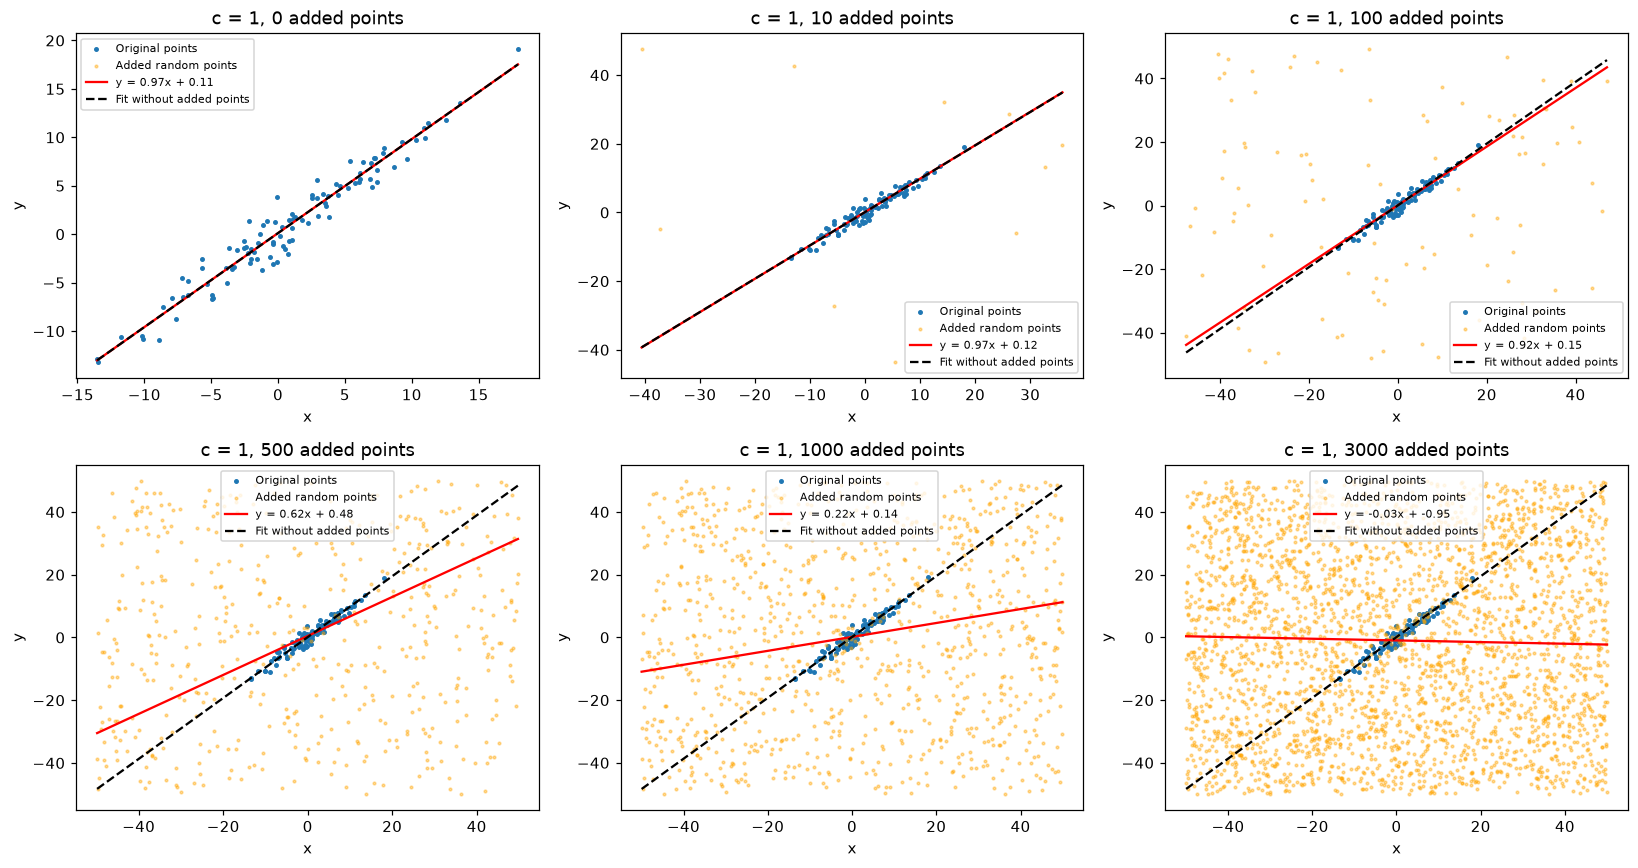

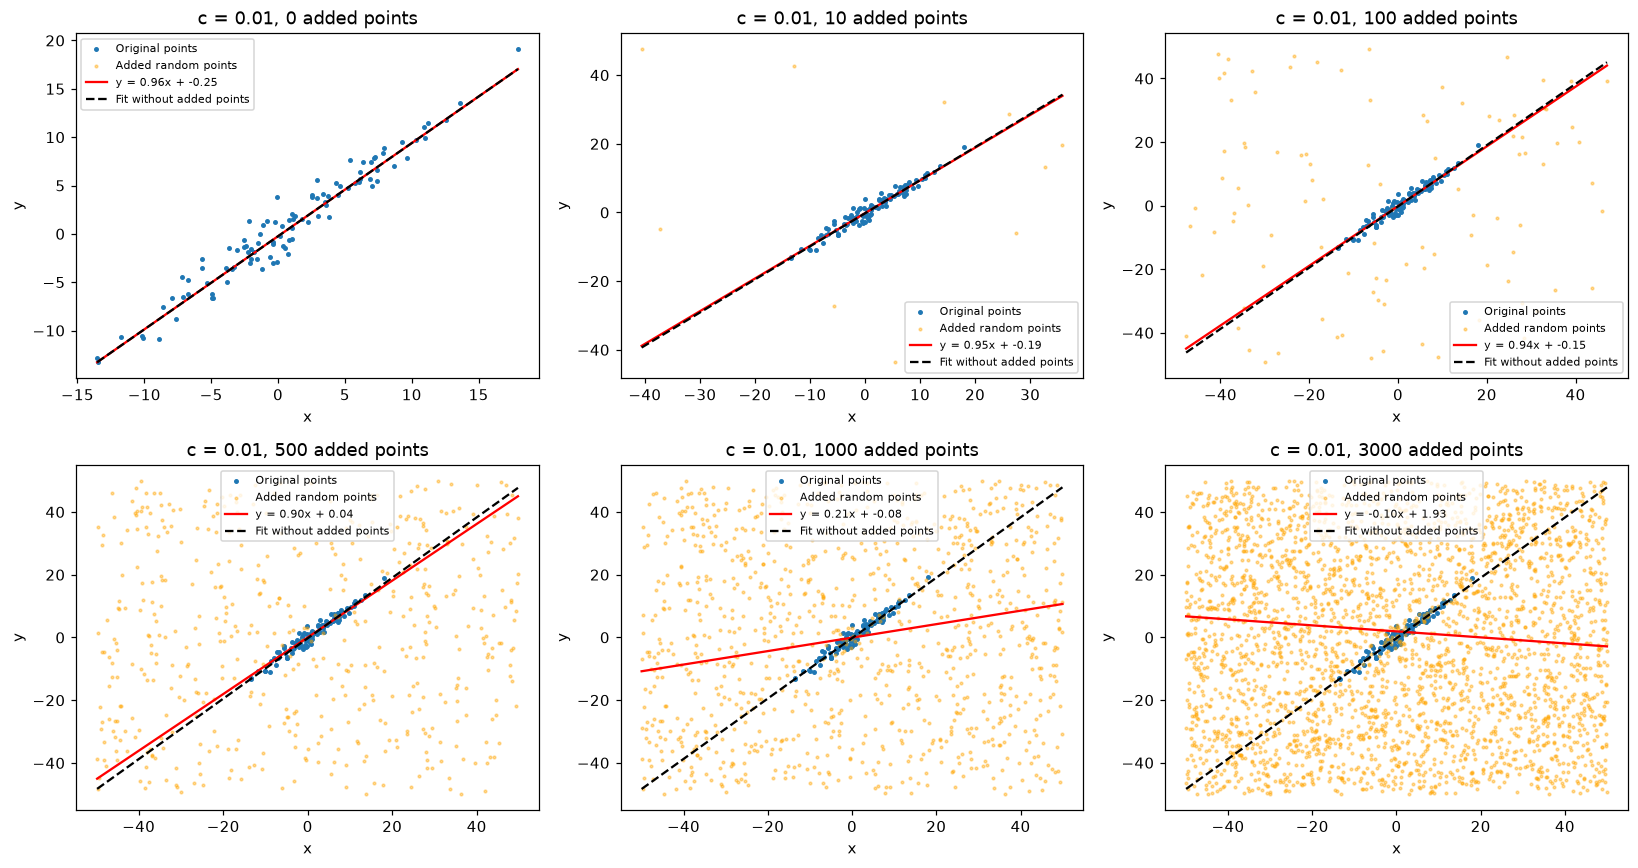

In [23]:
weights_6 = {}
errors_6 = {}
gradients_6 = {}

for c in c_values_6:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))

    for i in range(len(n_outliers_values)):
        n = n_outliers_values[i]
        data = datasets_6[n]
        ax = axes.flat[i]
        paths = []

        for start in [(1., 2.), (0., 0.)]:
            path = gradient_descent_backtrack(
                lambda p, w0, w1: sum_ro_2(p, w0, w1, c=c) / (len(p)*c**2),
                lambda p, w0, w1: dro_2(p, w0, w1, c=c) / (len(p)*c**2),
                start,
                data
            )
            paths.append(path)

        path = min(paths, key=lambda p: sum_ro_2(data, p[-1][0], p[-1][1], c))
        w0, w1 = path[-1]
        weights_6[(c, n)] = (w0, w1)

        y_hat = w0*points[:, 0] + w1
        errors_6[(c, n)] = np.sqrt(np.mean((points[:, 1] - y_hat)**2))
        gradient = dro_2(data, w0, w1, c) / (len(data)*c**2)
        gradients_6[(c, n)] = np.linalg.norm(gradient)

        x_line = np.array([data[:, 0].min(), data[:, 0].max()])
        ax.scatter(points[:, 0], points[:, 1], s=5, label="Original points")
        ax.scatter(outliers[:n, 0], outliers[:n, 1], s=3,
                   color="orange", alpha=0.4, label="Added random points")
        ax.plot(x_line, w0*x_line + w1, color="red",
                label=f"y = {w0:.2f}x + {w1:.2f}")
        w0_clean, w1_clean = weights_6[(c, 0)]
        ax.plot(x_line, w0_clean*x_line + w1_clean, "k--",
                label="Fit without added points")
        ax.set(xlabel="x", ylabel="y", title=f"c = {c}, {n} added points")
        ax.legend(fontsize=7)

        print(f"c={c}, added={n}: w0={w0:.3f}, w1={w1:.3f}, "
              f"RMSE={errors_6[(c, n)]:.3f}, "
              f"gradient norm={gradients_6[(c, n)]:.2e}")

    plt.tight_layout()
    plt.show()


To compare the results more clearly, we plot the RMSE of each fitted line evaluated on the same 100 original points. If this error increases, the line represents the original sample worse. We do not include the added points when calculating this error, because we want to measure how much the original relationship has been affected.


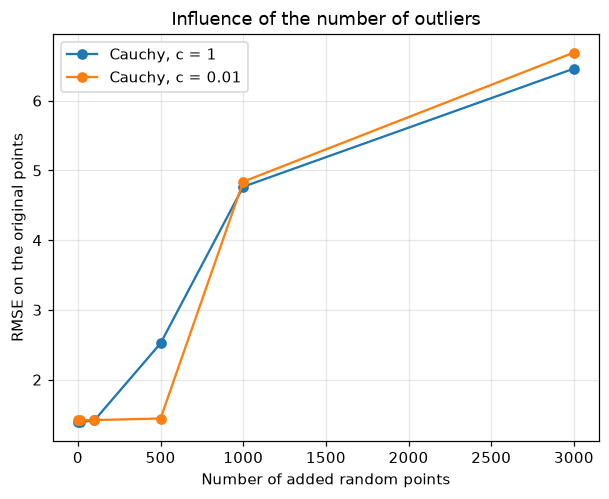

In [24]:
for c in c_values_6:
    errors = [errors_6[(c, n)] for n in n_outliers_values]
    plt.plot(n_outliers_values, errors, "o-", label=f"Cauchy, c = {c}")

plt.xlabel("Number of added random points")
plt.ylabel("RMSE on the original points")
plt.title("Influence of the number of outliers")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


We can observe that with a small number of added random points, the fitted line remains close to the line obtained without added points. However, when the number of random points is high, the line changes and the error on the original points increases.

For $c=1$, the slope changes from 0.971 without added points to -0.027 with 3000 added points. The RMSE on the original sample changes from 1.391 to 6.459.

For $c=0.01$, the slope changes from 0.963 without added points to -0.096 with 3000 added points. The RMSE on the original sample changes from 1.427 to 6.690.

The Cauchy function reduces the influence of each large residual, but this influence is not exactly zero. A large number of random points can collectively change which fitted line has a smaller objective value. In the last experiment, the 3000 added points account for about 96.8% of the 3100 observations, so the original linear pattern is only a small part of the sample.

Using a smaller $c$ does not guarantee a better result. With $c=0.01$, even many ordinary noisy observations are outside the approximately quadratic region of the loss. Moreover, the objective has local minima, so the fitted parameters can depend on the starting point. Trying two starting points reduces this problem but does not eliminate it.

These results describe this particular sample and way of generating outliers. They do not establish a universal number of outliers at which Cauchy regression fails. The final gradient norms printed above help check numerical convergence; if a fit reaches the iteration limit or its gradient is not small, its numerical accuracy should be checked before interpreting its result.